# Predicting athlete fatigue after a training session

Machine Learning project, Centrale Lyon, 2026. Nael El Dajani, Elliot Aimard Gaillot, Chloé Savy.

**Goal**: predict `fatigue_index` at the end of a training session, for football and basketball players.

1. Data
2. Preprocessing
3. Models
4. Results
5. Demo

In [1]:
import gradio as gr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LassoCV, LinearRegression
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor, plot_tree

# 1. Data

In [2]:
df_raw = pd.read_csv("data/multimodal_sports_injury_dataset_kaggle.csv")
df_raw = df_raw[df_raw["sport_type"].isin(["Soccer", "Basketball"])].reset_index(drop=True)
print(df_raw.shape, "|", df_raw["athlete_id"].nunique(), "athletes")
df_raw.head(3)

(8896, 29) | 90 athletes


,athlete_id,heart_rate,body_temperature,hydration_level,sleep_quality,recovery_score,stress_level,muscle_activity,joint_angles,gait_speed,...,training_intensity,training_duration,training_load,fatigue_index,injury_occurred,session_id,sport_type,gender,age,bmi
0,1,NaN,37.048668,76.481477,5.466370,77.899691,0.375825,10.000000,126.480118,2.654327,...,5.678475,79.106564,548.417962,45.028687,0,1,Basketball,Female,18,25.105748
1,1,40.000000,36.929536,72.363938,6.899090,74.845323,0.279165,310.293156,157.631630,3.431107,...,NaN,116.954654,538.043815,42.254717,2,2,Basketball,Female,18,25.105748
2,1,76.174609,36.334841,100.000000,9.574152,83.538316,0.334061,158.659094,81.766287,0.800000,...,6.643242,96.354742,647.784339,61.870056,0,3,Basketball,Female,18,25.105748


In [3]:
df_raw["fatigue_index"].describe()

count    8896.000000
mean       59.485050
std        25.142969
min        15.000000
25%        41.501922
50%        57.112199
75%        74.818826
max       270.193219
Name: fatigue_index, dtype: float64

In [4]:
q = df_raw["fatigue_index"].quantile([.1,.25,.5,.75,.9,.95])
print(q)

0.10     28.474709
0.25     41.501922
0.50     57.112199
0.75     74.818826
0.90     92.220981
0.95    104.250557
Name: fatigue_index, dtype: float64


90 athletes, about 99 sessions each.

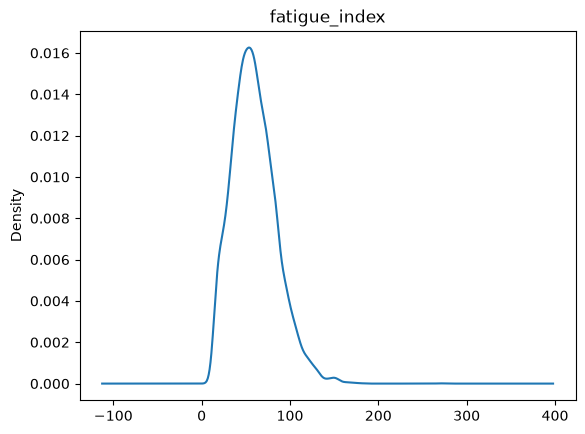

In [5]:

df_raw["fatigue_index"].plot(kind="density", title="fatigue_index")
plt.show()

In [6]:
df_raw.isna().sum()[lambda s: s > 0]

heart_rate            207
hydration_level       237
sleep_quality         281
muscle_activity       348
gait_speed            247
training_intensity    390
dtype: int64

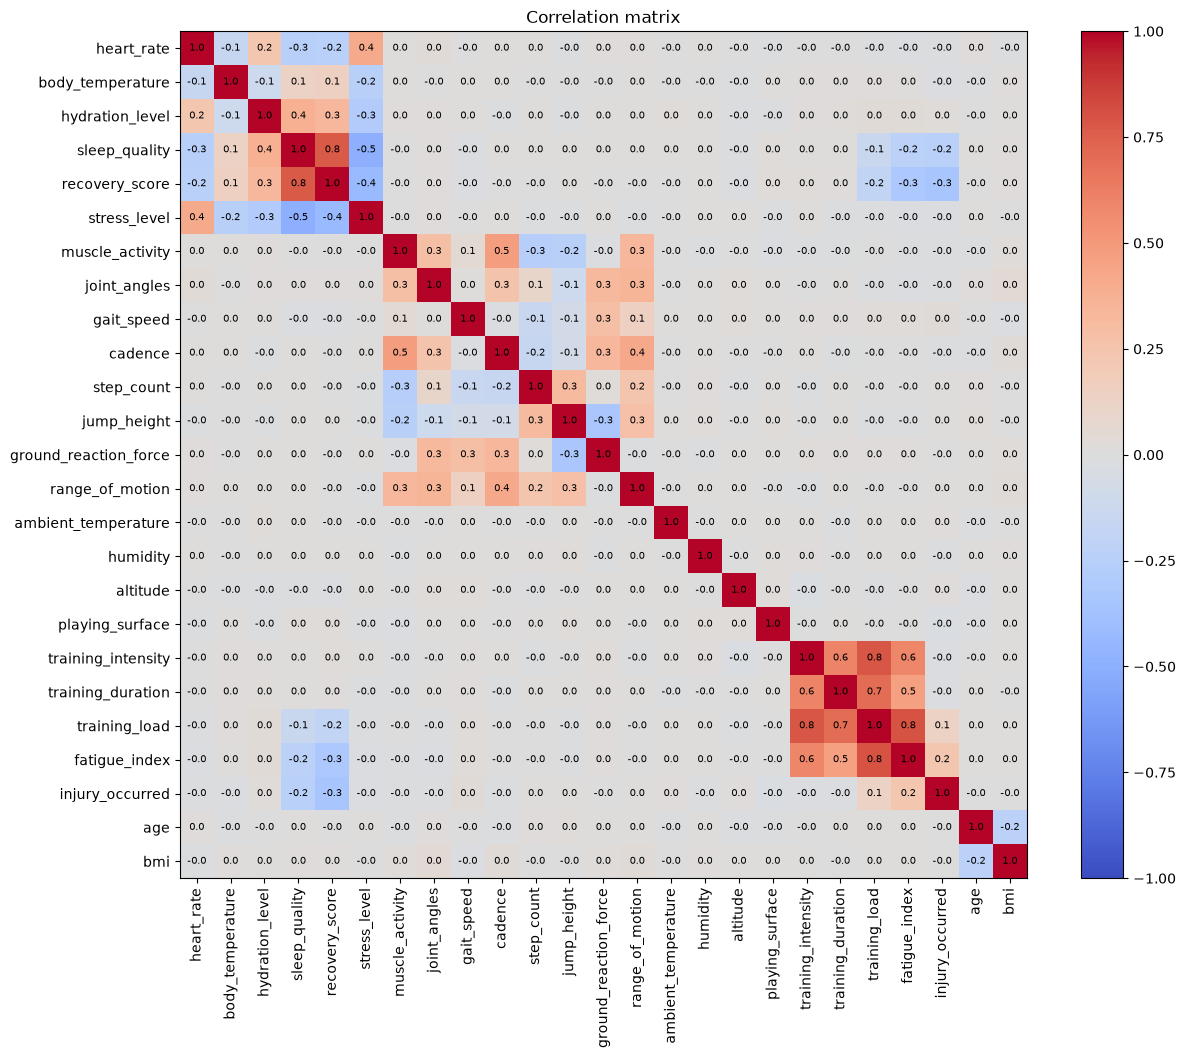

In [7]:
corr = df_raw.select_dtypes("number").drop(columns=["athlete_id", "session_id"]).corr()

plt.figure(figsize=(14, 11))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
plt.title("Correlation matrix")
plt.show()

In [8]:
corr["fatigue_index"].drop("fatigue_index").sort_values(key=abs, ascending=False).round(2).head(8)

training_load         0.80
training_intensity    0.59
training_duration     0.47
recovery_score       -0.32
injury_occurred       0.23
sleep_quality        -0.23
hydration_level       0.02
stress_level         -0.02
Name: fatigue_index, dtype: float64

`training_load` dominates (r = 0.80). It is built from `training_intensity` and `training_duration`, hence their correlation with it.

# 2. Preprocessing

- `athlete_id`, `session_id`: identifiers, removed.
- `injury_occurred`: removed. The injury is an outcome of the session, not something known when predicting fatigue.
- `gender`, `sport_type`: two values each, encoded 0/1.
- `playing_surface`: 5 unordered categories (0 to 4), one-hot encoded.
- Missing values: filled with the **train** medians only.

In [9]:
def prepare(rows):
    X = rows.drop(columns=["athlete_id", "session_id", "injury_occurred", "fatigue_index"], errors="ignore")
    X["gender"] = (X["gender"] == "Male").astype(int)
    X["sport_type"] = (X["sport_type"] == "Soccer").astype(int)
    X["playing_surface"] = pd.Categorical(X["playing_surface"], categories=[0, 1, 2, 3, 4])
    return pd.get_dummies(X, columns=["playing_surface"], prefix="surface", drop_first=True, dtype=int)

Random split of the sessions: 60% train, 20% validation, 20% test.

In [10]:
train_raw, rest_raw = train_test_split(df_raw, test_size=0.4, random_state=42)
valid_raw, test_raw = train_test_split(rest_raw, test_size=0.5, random_state=42)

medians = prepare(train_raw).median()

X_train, y_train = prepare(train_raw).fillna(medians), train_raw["fatigue_index"]
X_valid, y_valid = prepare(valid_raw).fillna(medians), valid_raw["fatigue_index"]
X_test, y_test = prepare(test_raw).fillna(medians), test_raw["fatigue_index"]

print("train:", X_train.shape, "| valid:", X_valid.shape, "| test:", X_test.shape)

train: (5337, 28) | valid: (1779, 28) | test: (1780, 28)


# 3 ~ Models

In [11]:
def print_score(m):
    print("R2 train   :", round(m.score(X_train, y_train), 3))
    print("R2 valid   :", round(m.score(X_valid, y_valid), 3))
    print("RMSE valid :", round(root_mean_squared_error(y_valid, m.predict(X_valid)), 2))

## A ~ Decision tree

Rule used for every model: keep the best R2 valid **among settings where R2 valid >= R2 train** (no overfitting).

In [12]:
for d in range(1, 11):
    t = DecisionTreeRegressor(max_depth=d, random_state=42).fit(X_train, y_train)
    print(d, "| train:", round(t.score(X_train, y_train), 3), "| valid:", round(t.score(X_valid, y_valid), 3))

1 | train: 0.408 | valid: 0.444
2 | train: 0.568 | valid: 0.578
3 | train: 0.63 | valid: 0.634
4 | train: 0.663 | valid: 0.652
5 | train: 0.692 | valid: 0.658


6 | train: 0.717 | valid: 0.645


7 | train: 0.747 | valid: 0.625
8 | train: 0.78 | valid: 0.588
9 | train: 0.816 | valid: 0.545


10 | train: 0.852 | valid: 0.513


Depth 3 is the deepest tree with R2 valid >= R2 train. From depth 6, R2 valid drops: the tree learns the training data by heart.

R2 train   : 0.63
R2 valid   : 0.634
RMSE valid : 14.91


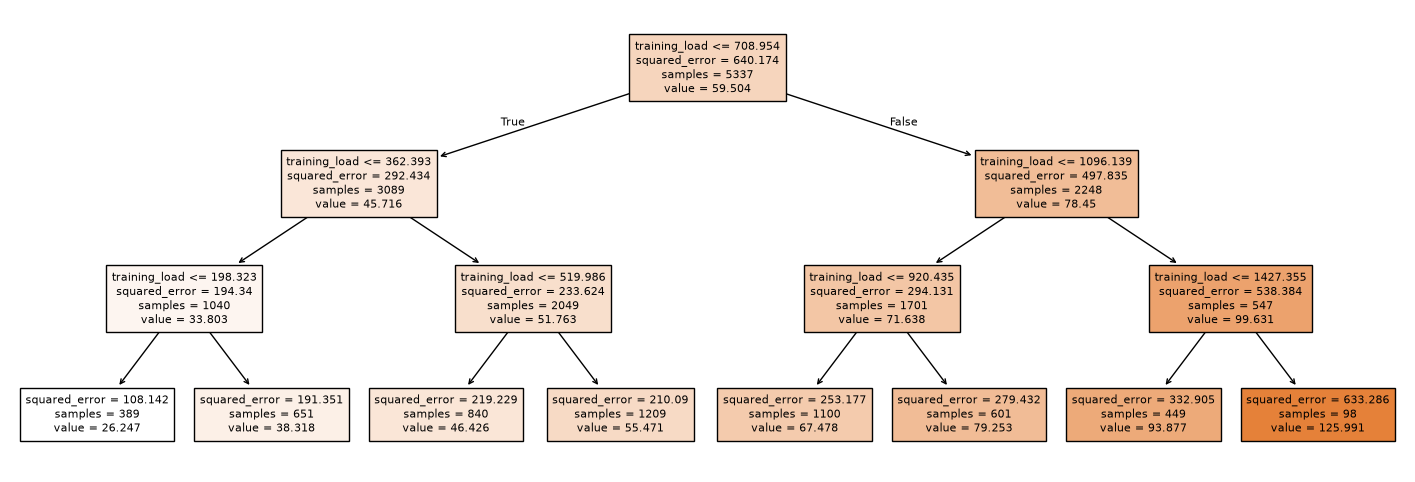

In [13]:
tree = DecisionTreeRegressor(max_depth=3, random_state=42)
tree.fit(X_train, y_train)
print_score(tree)

plt.figure(figsize=(18, 6))
plot_tree(tree, feature_names=X_train.columns, filled=True, fontsize=8)
plt.show()

## B ~ Random forest

In [14]:
results = []
for depth in [2, 3, 4, 5, 6, 8, 10]:
    for leaf in [1, 5, 10, 25, 50]:
        for features_part in [1.0, 0.5, 0.33]:
            m = RandomForestRegressor(n_estimators=100, max_depth=depth, min_samples_leaf=leaf,
                                      max_features=features_part, random_state=42, n_jobs=-1)
            m.fit(X_train, y_train)
            results.append({"max_depth": depth, "min_samples_leaf": leaf, "max_features": features_part,
                            "R2 train": m.score(X_train, y_train), "R2 valid": m.score(X_valid, y_valid)})

results = pd.DataFrame(results)
results["gap"] = results["R2 train"] - results["R2 valid"]
acceptable = results[results["R2 valid"] >= results["R2 train"]]
best = acceptable.sort_values("R2 valid", ascending=False).iloc[0]
acceptable.sort_values("R2 valid", ascending=False).head(5).round(3)

,max_depth,min_samples_leaf,max_features,R2 train,R2 valid,gap
42,4,50,1.00,0.675,0.677,-0.002
43,4,50,0.50,0.662,0.668,-0.006
40,4,25,0.50,0.665,0.667,-0.002
59,5,50,0.33,0.651,0.653,-0.002
24,3,25,1.00,0.647,0.648,-0.002


In [15]:
rf = RandomForestRegressor(n_estimators=100, max_depth=int(best["max_depth"]),
                           min_samples_leaf=int(best["min_samples_leaf"]), max_features=best["max_features"],
                           oob_score=True, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print_score(rf)
print("R2 OOB     :", round(rf.oob_score_, 3))

R2 train   : 0.675
R2 valid   : 0.677
RMSE valid : 14.01
R2 OOB     : 0.657


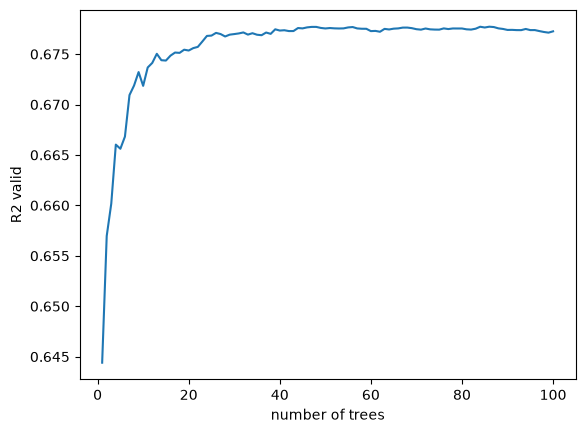

In [16]:
preds = np.stack([t.predict(X_valid.values) for t in rf.estimators_])
plt.plot(range(1, 101), [r2_score(y_valid, preds[:k].mean(axis=0)) for k in range(1, 101)])
plt.xlabel("number of trees")
plt.ylabel("R2 valid")
plt.show()

## C ~ Linear regression and Lasso

In [17]:
linear = LinearRegression()
linear.fit(X_train, y_train)
print_score(linear)

equation = f"fatigue_index = {linear.intercept_:.2f}"
for name, coef in zip(X_train.columns, linear.coef_):
    equation += f" + ({coef:.2f} × {name})"
print(equation)

R2 train   : 0.693
R2 valid   : 0.692
RMSE valid : 13.69
fatigue_index = 25.64 + (-0.06 × heart_rate) + (0.33 × body_temperature) + (0.15 × hydration_level) + (-0.26 × sleep_quality) + (-0.29 × recovery_score) + (-9.11 × stress_level) + (-0.00 × muscle_activity) + (-0.01 × joint_angles) + (-0.23 × gait_speed) + (0.00 × cadence) + (-0.00 × step_count) + (-0.43 × jump_height) + (0.00 × ground_reaction_force) + (0.01 × range_of_motion) + (-0.01 × ambient_temperature) + (0.01 × humidity) + (0.00 × altitude) + (-0.02 × training_intensity) + (-0.13 × training_duration) + (0.07 × training_load) + (0.63 × sport_type) + (-0.22 × gender) + (0.01 × age) + (0.13 × bmi) + (-1.08 × surface_1) + (-0.10 × surface_2) + (-0.03 × surface_3) + (-0.76 × surface_4)


In [18]:
lasso = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=42))
lasso.fit(X_train, y_train)
print_score(lasso)

coefs = pd.Series(lasso[-1].coef_, index=X_train.columns)
print("\nKept variables (standardized coefficients):")
print(coefs[coefs != 0].sort_values(key=abs, ascending=False).round(2))
print("\nRemoved:", list(coefs[coefs == 0].index))

R2 train   : 0.692
R2 valid   : 0.692
RMSE valid : 13.68

Kept variables (standardized coefficients):
training_load        21.19
recovery_score       -4.84
training_duration    -3.00
stress_level         -1.48
hydration_level       1.36
heart_rate           -0.76
surface_1            -0.19
sport_type            0.14
bmi                   0.13
sleep_quality        -0.13
muscle_activity      -0.12
surface_4            -0.07
joint_angles         -0.02
dtype: float64

Removed: ['body_temperature', 'gait_speed', 'cadence', 'step_count', 'jump_height', 'ground_reaction_force', 'range_of_motion', 'ambient_temperature', 'humidity', 'altitude', 'training_intensity', 'gender', 'age', 'surface_2', 'surface_3']


## D ~ Cross-validation

One validation split depends on which sessions it contains. 5-fold cross-validation on train + valid gives a more stable comparison.

In [19]:
X_trval = pd.concat([X_train, X_valid])
y_trval = pd.concat([y_train, y_valid])

models = {"Decision tree": tree, "Random forest": rf, "Linear regression": linear, "Lasso": lasso}

cv = {}
for name, m in models.items():
    scores = cross_val_score(clone(m), X_trval, y_trval, cv=KFold(5, shuffle=True, random_state=42), scoring="r2")
    cv[name] = {"R2 mean": scores.mean(), "R2 std": scores.std()}

cv = pd.DataFrame(cv).T.sort_values("R2 mean", ascending=False)
cv.round(3)

,R2 mean,R2 std
Lasso,0.691,0.007
Linear regression,0.690,0.007
Random forest,0.662,0.012
Decision tree,0.624,0.010


# 4 ~ Results

In [20]:
test = {}
for name, m in models.items():
    final = clone(m).fit(X_trval, y_trval)
    pred = final.predict(X_test)
    test[name] = {"R2 test": r2_score(y_test, pred), "RMSE test": root_mean_squared_error(y_test, pred)}
    models[name] = final

test = pd.DataFrame(test).T.sort_values("R2 test", ascending=False)
test.round(3)

,R2 test,RMSE test
Lasso,0.691,13.965
Linear regression,0.691,13.969
Random forest,0.664,14.565
Decision tree,0.621,15.464


In [21]:
best_name = cv.index[0]
final_model = models[best_name]
print("Final model (best cross-validation score):", best_name)

Final model (best cross-validation score): Lasso


Which variables matter? Permutation importance on the test set: how much R2 drops when one variable is shuffled.

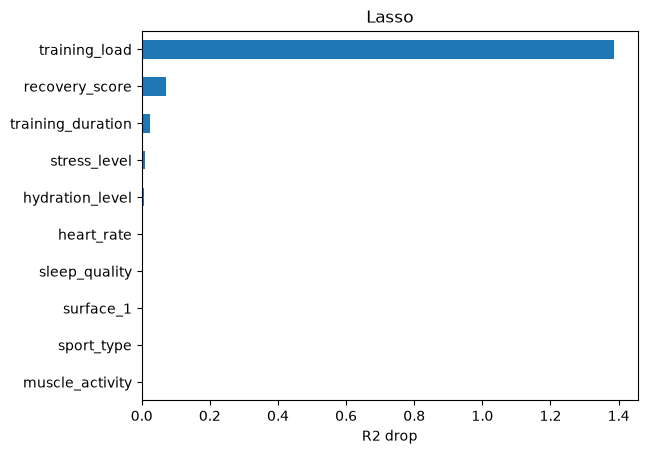

In [22]:
perm = permutation_importance(final_model, X_test, y_test, n_repeats=5, random_state=42)
pd.Series(perm.importances_mean, index=X_test.columns).sort_values().tail(10).plot.barh(title=best_name)
plt.xlabel("R2 drop")
plt.show()

In [23]:
drops = {"all variables": [],
         "without training_load": ["training_load"],
         "without the 3 training variables": ["training_load", "training_intensity", "training_duration"]}

for label, cols in drops.items():
    scores = cross_val_score(clone(final_model), X_trval.drop(columns=cols), y_trval,
                             cv=KFold(5, shuffle=True, random_state=42), scoring="r2")
    print(f"{label:35s} R2 = {scores.mean():.3f}")

all variables                       R2 = 0.691


without training_load               R2 = 0.512


without the 3 training variables    R2 = 0.142


# 5 ~ Demo

Simulate an unseen session.

In [24]:
sessions = {f"Athlete {a} - session {s}": i
            for i, a, s in zip(test_raw.index, test_raw["athlete_id"], test_raw["session_id"])}



def simulate(sport, gender, training_load, training_intensity, training_duration,
             recovery_score, sleep_quality, stress_level):
    row = medians.to_frame().T
    row[["sport_type", "gender"]] = [int(sport == "Soccer"), int(gender == "Male")]
    row[["training_load", "training_intensity", "training_duration"]] = [training_load, training_intensity, training_duration]
    row[["recovery_score", "sleep_quality", "stress_level"]] = [recovery_score, sleep_quality, stress_level]

    pred = final_model.predict(row)[0]

    if pred >= q[.95]:
        phrase = "The predicted fatigue is in the 5% most tiring sessions."
    elif pred >= q[.9]:
        phrase = "The predicted fatigue is in the 10% most tiring sessions."
    elif pred >= q[.75]:
        phrase = "The predicted fatigue is in the 25% most tiring sessions."
    elif pred >= q[.5]:
        phrase = "The predicted fatigue is above the median session."
    elif pred >= q[.25]:
        phrase = "The predicted fatigue is below the median session."
    elif pred >= q[.1]:
        phrase = "The predicted fatigue is in the 25% least tiring sessions."
    else:
        phrase = "The predicted fatigue is in the 10% least tiring sessions."

    return f"Predicted fatigue: {pred:.0f}\n{phrase}"

tab2 = gr.Interface(simulate, [gr.Radio(["Soccer", "Basketball"], value="Soccer"),
                               gr.Radio(["Male", "Female"], value="Male"),
                               gr.Slider(150, 2600, 600, label="training_load"),
                               gr.Slider(2, 10, 6, label="training_intensity"),
                               gr.Slider(30, 180, 90, label="training_duration"),
                               gr.Slider(0, 100, 55, label="recovery_score"),
                               gr.Slider(0, 10, 6, label="sleep_quality"),
                               gr.Slider(0.1, 0.95, 0.4, label="stress_level")], "text")
gr.TabbedInterface([tab2], [ "Simulate a session"]).launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
